![Original climate-globe illustration introducing A Pacific story in five evidence panels; illustrative, not a data map](assets/atlas-splash.png)

# 29 · A Pacific story in five evidence panels

**Guiding question:** Can you tell a compelling story without outrunning the evidence?

**Data:** Real C3S/ECMWF ERA5 Climate Pulse CSV snapshots retrieved 2026-11-20; CC BY 4.0  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=29-enso-story-lab.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

Build the narrative in five steps: **locate → compare → contextualise →
        inspect time → state limits**. Each panel should answer one question and show
        the evidence needed to assess its claim. A globe supplies geographic context;
        a line chart is better for small temporal differences. A year–month heatmap
        keeps every complete month visible without occlusion.

        The companion storymap uses the same snapshots and downloadable GeoJSON.
        In the 3D scene below, x is year, y is calendar month, and z is an anomaly in °C.
        It is a data surface, not ocean topography. The partial 2026 row is omitted from
        the scene so interpolation never implies unpublished months. The dashboard retains
        available 2026 months individually. Read every conclusion with its as-of date.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Make a scene and its flat alternative

Figure({
    'data': [{'cmax': 4,
              'cmin': -4,
              'colorbar': {'title': {'text': 'Δ °C'}},
              'colorscale': [[0.0, 'rgb(5,48,97)'], [0.1, 'rgb(33,102,172)'],
                             [0.2, 'rgb(67,147,195)'], [0.3, 'rgb(146,197,222)'],
                             [0.4, 'rgb(209,229,240)'], [0.5, 'rgb(247,247,247)'],
                             [0.6, 'rgb(253,219,199)'], [0.7, 'rgb(244,165,130)'],
                             [0.8, 'rgb(214,96,77)'], [0.9, 'rgb(178,24,43)'],
                             [1.0, 'rgb(103,0,31)']],
              'type': 'surface',
              'x': {'bdata': ('uwcAALwHAAC9BwAAvgcAAL8HAADABw' ... 'AA5QcAAOYHAADnBwAA6AcAAOkHAAA='),
                    'dtype': 'i4'},
              'y': {'bdata': 'AQAAAAIAAAADAAAABAAAAAUAAAAGAAAABwAAAAgAAAAJAAAACgAAAAsAAAAMAAAA', 'dtype': 'i4'},
              'z': {'bdata': ('jSjtDb4wib+srdhfdk/iP5LLf0i/ff' ... 'QNT68UAEAibHh6pSznv8e6uI0G8OS/'),
                    'dtype': 'f8',
                    'shape': '12, 47'}}],
    'layout': {'font': {'size': 14},
               'height': 470,
               'margin': {'b': 65, 'l': 65, 'r': 45, 't': 90},
               'scene': {'xaxis': {'title': {'text': 'Year'}},
                         'yaxis': {'title': {'text': 'Month'}},
                         'zaxis': {'title': {'text': 'Anomaly (°C)'}}},
               'template': '...',
               'title': {'text': 'ERA5 Niño 3.4 · 1979–2025 monthly anomaly surface'}}
})

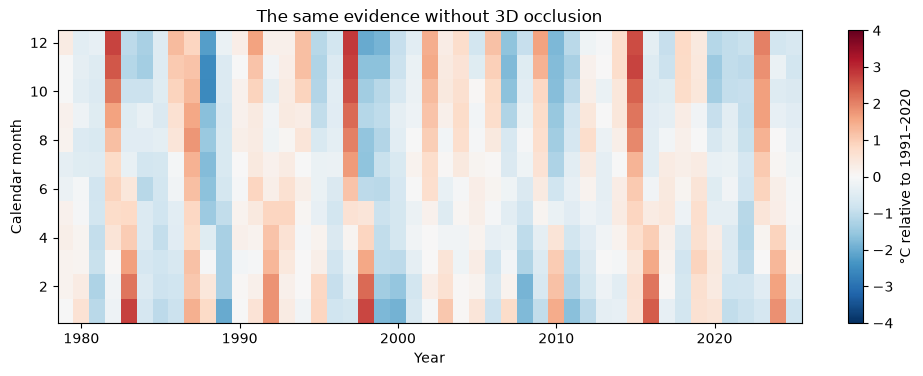

In [2]:
from pulse_helpers import (
    load_pulse, complete_months, rank_same_month, region_rings, region_geojson,
    region_map, region_globe, REGIONS, ANOM, REL, CREDIT, BASE,
)
df = load_pulse()
complete = df[df.year <= 2025]
matrix = complete.pivot(index="month", columns="year", values=ANOM)
assert matrix.notna().all().all()
fig = go.Figure(go.Surface(x=matrix.columns, y=matrix.index, z=matrix.to_numpy(),
    colorscale="RdBu_r", cmin=-4, cmax=4, colorbar=dict(title="Δ °C")))
fig.update_layout(title="ERA5 Niño 3.4 · 1979–2025 monthly anomaly surface", scene=dict(xaxis_title="Year", yaxis_title="Month", zaxis_title="Anomaly (°C)"))
show(fig)
fig, ax = plt.subplots(figsize=(12, 3.8))
image = ax.imshow(matrix, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-4, vmax=4,
                  extent=[1978.5,2025.5,.5,12.5])
ax.set(xlabel="Year", ylabel="Calendar month", title="The same evidence without 3D occlusion")
fig.colorbar(image, ax=ax, label="°C relative to 1991–2020"); plt.show()

## Write an evidence card that can travel with the story

In [3]:
latest = df.iloc[-1]
rank = rank_same_month(df, latest.date)
card = {
    "question": "How unusual is the latest archived October Niño 3.4 SST?",
    "as_of": "2026-11-20", "month": str(latest.date.date()),
    "finding": f"Traditional anomaly {latest[ANOM]:.4f} °C; rank {rank['rank']} of {rank['n']} matching calendar months.",
    "relative_index_c": float(latest[REL]),
    "method": "Published regional monthly values; 1991–2020 reference; competition rank.",
    "source": CREDIT, "doi": "10.24381/cds.f17050d7", "licence": "CC-BY-4.0",
    "transformation": "Original charts and region geometry; no reconstruction of SST pixels.",
    "limitation": "Snapshot, not live; regional mean, not local hazard; rank is not a return period.",
}
display(pd.Series(card).to_frame("Evidence card"))
out = Path("exports"); out.mkdir(exist_ok=True)
(out/"enso-story-card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
from IPython.display import Markdown
display(Markdown(f"[Explore the interactive Pulse lab]({BASE}pulse/) · [Read the five-panel storymap]({BASE}stories/enso/)"))

,Evidence card
question,How unusual is the latest archived October Niñ...
as_of,2026-11-20
month,2026-10-01
finding,Traditional anomaly 3.2345 °C; rank 1 of 48 ma...
relative_index_c,2.6089
method,Published regional monthly values; 1991–2020 r...
source,Copernicus Climate Change Service (C3S) / ECMW...
doi,10.24381/cds.f17050d7
licence,CC-BY-4.0
transformation,Original charts and region geometry; no recons...


[Explore the interactive Pulse lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/pulse/) · [Read the five-panel storymap](https://jltobias.github.io/JupyterLite-C3S-Atlas/stories/enso/)

## Try it and explain

Write a second story about another region or archived month. Change the question and comparison set together, and include a counterexample or limitation.

**Interpretation check:** A defensible story preserves its source, date, spatial support, baseline, transformations, and denominator. Visual drama cannot supply missing evidence.

## Transfer to the official tools

Use the official Pulse share/export controls to save a complementary view, then compare it with your own card. Link official tutorial videos at their source instead of copying publisher media.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [C3S Climate Pulse 2.0 announcement (10 November 2026)](https://climate.copernicus.eu/new-version-climate-pulse-provides-new-monitoring-el-nino-conditions)
- [Climate Pulse FAQs and methodology](https://pulse.climate.copernicus.eu/faqs)
- [Climate Pulse credits and citations](https://pulse.climate.copernicus.eu/credits)
- [ERA5 monthly data: C3S/ECMWF and ERA5 contributors](https://doi.org/10.24381/cds.f17050d7)
- [Hersbach et al. (2020): The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803)
- [GeoLibre projects and story-map authoring](https://geolibre.app/user-guide/projects/)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).